# 02: Feature selection

Which features carry signal, and which duplicate each other? This notebook shows the feature-selection method
step by step and is material for the report. **It does not choose the features.** Choosing them here and then
cross-validating on the same rows would be leakage. The models select features inside each CV fold, on that fold's
training rows only, with the same method (`src/selection.py`, `feature_selection` in `config.yaml`).

**Data:** only the **development rows** (the rows before the hold-out, minus the 90-day gap), with the same
time-ordered folds as `compare`. The hold-out is never touched.

1. Permutation importance per raw column (both tasks)
2. Impurity importance, and why it is not used
3. Correlation between numeric features
4. Decision table: what the rules would drop on all development rows
5. Illustration only: cross-validation with all features against that set (optimistic, see section 5)

`random_noise` stays a candidate on purpose: a sound method must rank it at the bottom.

In [1]:
import os, sys
os.chdir("..")                 # repository root: config.yaml and data/ paths are relative to it
sys.path.insert(0, ".")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn.base import clone
from sklearn.inspection import permutation_importance

from main import load_training_splits
from src.data import load_config
from src.evaluate import cross_validate_pipeline
from src.features import split_features_target
from src.model import build_pipeline

pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 80)
sns.set_theme(style="whitegrid")

CONFIG = load_config()
CONFIG["feature_selection"]["method"] = "none"   # probe pipelines here must use every candidate feature
TASKS = ["classification", "regression"]
CATEGORICAL = CONFIG["preprocessing"]["categorical_features"]
# The probe model for importance: a random forest, the CV leader in both tasks
FOREST = {"type": "random_forest", "params": {"n_estimators": 200, "min_samples_leaf": 5, "n_jobs": -1}}
SCORING = {"classification": "roc_auc", "regression": "neg_root_mean_squared_error"}
N_REPEATS = 5

data = {}
for task in TASKS:
    _, dev, _, cv = load_training_splits(CONFIG, task)
    X, y = split_features_target(dev, CONFIG, task)
    data[task] = (X, y, cv)
    print(f"{task}: {len(X)} development rows, {X.shape[1]} candidate features, {cv.get_n_splits()} folds")

classification: 5024 development rows, 49 candidate features, 5 folds
regression: 2656 development rows, 49 candidate features, 5 folds


## 1. Permutation importance per raw column

For each time-ordered fold, a random forest pipeline (preprocessing included) is fitted on the training rows. Then,
on the validation rows, one **raw** column at a time is shuffled and the drop in score is recorded
(ROC-AUC for classification, RMSE in EUR for regression), `N_REPEATS` times per fold.

- Shuffling the raw column moves a categorical as one feature (all its one-hot levels together).
- Validation rows are later than the training rows, as in real use.
- A feature with no signal, such as `random_noise`, scores about 0: shuffling it changes nothing.

Result per feature: the mean and std of the score drop over 5 folds × 5 shuffles.

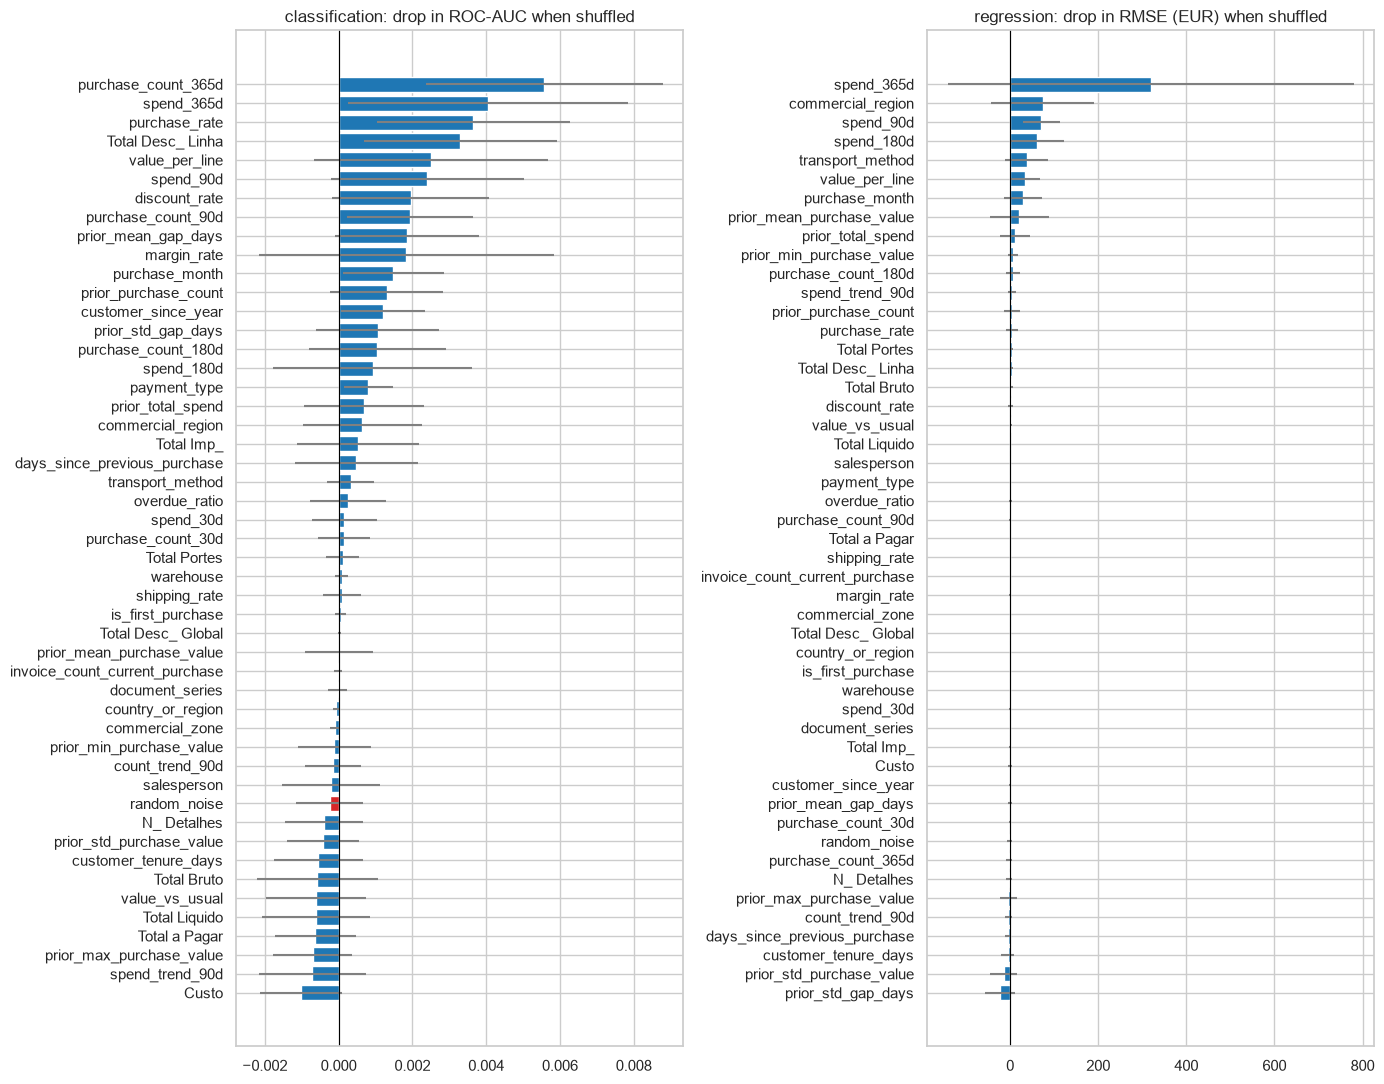

classification: random_noise rank 39.0 of 49, importance -0.0002461 ± 0.0008992
regression: random_noise rank 41.0 of 49, importance -1.462 ± 4.659


In [2]:
def raw_column(encoded: str) -> str:
    """Maps an encoded column name back to its raw column (one-hot level or missing indicator)."""
    name = encoded.split("__", 1)[1].removeprefix("missingindicator_")
    return next((c for c in CATEGORICAL if name.startswith(c + "_")), name)

permutation, impurity = {}, {}
for task in TASKS:
    X, y, cv = data[task]
    drops, splits = [], []
    for train_idx, val_idx in cv.split(X):
        model = build_pipeline(task, CONFIG, FOREST).fit(X.iloc[train_idx], y.iloc[train_idx])
        result = permutation_importance(model, X.iloc[val_idx], y.iloc[val_idx], scoring=SCORING[task],
                                        n_repeats=N_REPEATS, random_state=CONFIG["seed"])
        drops.append(result.importances)
        names = model.named_steps["prep"].get_feature_names_out()
        splits.append(pd.Series(model.named_steps["model"].feature_importances_,
                                index=[raw_column(n) for n in names]).groupby(level=0).sum())
    drops = np.hstack(drops)
    table = pd.DataFrame({"mean": drops.mean(axis=1), "std": drops.std(axis=1)}, index=X.columns)
    permutation[task] = table.sort_values("mean", ascending=False).assign(rank=lambda t: range(1, len(t) + 1))
    impurity[task] = pd.concat(splits, axis=1).mean(axis=1).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 11))
for ax, task in zip(axes, TASKS):
    table = permutation[task].iloc[::-1]
    colors = ["tab:red" if name == "random_noise" else "tab:blue" for name in table.index]
    ax.barh(table.index, table["mean"], xerr=table["std"], color=colors, ecolor="grey")
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{task}: drop in {'ROC-AUC' if task == 'classification' else 'RMSE (EUR)'} when shuffled")
plt.tight_layout()
plt.show()

for task in TASKS:
    noise = permutation[task].loc["random_noise"]
    print(f"{task}: random_noise rank {noise['rank']} of {len(permutation[task])}, "
          f"importance {noise['mean']:.4g} ± {noise['std']:.4g}")

## 2. Impurity importance, and why it is not used

The forest's built-in importance (impurity decrease, summed over each column's one-hot levels) is computed on the
training rows. It rewards columns with many distinct values, because they offer many split points, and
`random_noise` has a distinct value on every row.

In [3]:
comparison = pd.DataFrame({
    f"{task} {kind}": ranks
    for task in TASKS
    for kind, ranks in [("permutation rank", permutation[task]["rank"]),
                        ("impurity rank", impurity[task].rank(ascending=False).astype(int))]
})
print(comparison.loc[["random_noise"]].to_string())
comparison.sort_values("classification permutation rank").head(15)

              classification permutation rank  classification impurity rank  regression permutation rank  regression impurity rank
random_noise                               39                            15                           41                        17


,classification permutation rank,classification impurity rank,regression permutation rank,regression impurity rank
purchase_count_365d,1,4,42,37
spend_365d,2,2,1,1
purchase_rate,3,1,14,9
Total Desc_ Linha,4,10,16,26
value_per_line,5,6,6,2
spend_90d,6,5,3,3
discount_rate,7,13,18,28
purchase_count_90d,8,14,24,38
prior_mean_gap_days,9,9,39,20
margin_rate,10,7,28,21


## 3. Correlation between numeric features

Permutation importance under-rates features that have a near-copy: when one is shuffled the forest leans on the
other, so both look weak although the information matters. Spearman correlation (rank-based, robust to the skewed
amounts) finds these families. Features are grouped so that every pair inside a group has |r| ≥ 0.9.

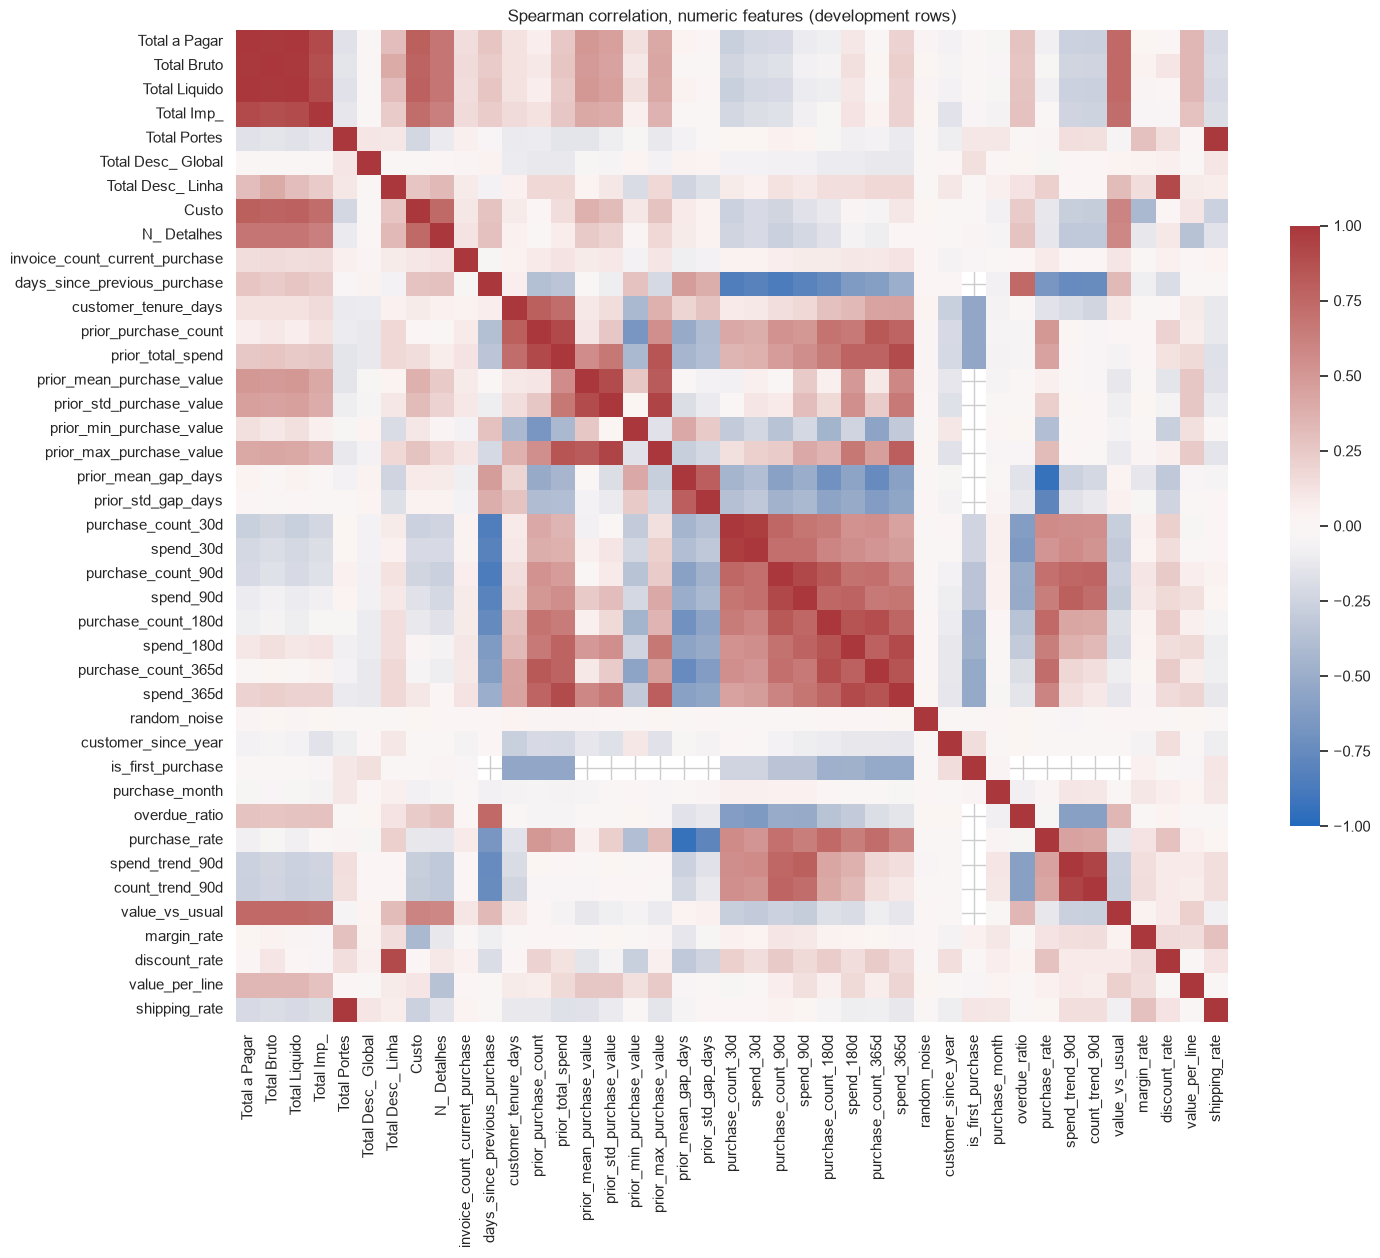

|r| 0.99-0.99: Total Portes, shipping_rate
|r| 0.91-0.91: prior_purchase_count, prior_total_spend
|r| 0.94-0.94: spend_trend_90d, count_trend_90d
|r| 0.92-0.92: purchase_count_90d, spend_90d
|r| 0.96-0.96: purchase_count_30d, spend_30d
|r| 0.90-0.90: Total Desc_ Linha, discount_rate
|r| 0.94-0.94: prior_mean_gap_days, purchase_rate
|r| 0.90-0.90: spend_180d, spend_365d
|r| 0.94-0.94: prior_std_purchase_value, prior_max_purchase_value
|r| 0.99-1.00: Total a Pagar, Total Bruto, Total Liquido


In [4]:
X_all = data["classification"][0]
numeric = [c for c in X_all.columns if c not in CATEGORICAL]
corr = X_all[numeric].corr(method="spearman")

plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="vlag", vmin=-1, vmax=1, square=True, xticklabels=True, yticklabels=True, cbar_kws={"shrink": 0.6})
plt.title("Spearman correlation, numeric features (development rows)")
plt.show()

distance = squareform(1 - corr.abs().fillna(0).values, checks=False)
group_id = pd.Series(fcluster(linkage(distance, method="complete"), t=0.1, criterion="distance"), index=numeric)
families = [list(g.index) for _, g in group_id.groupby(group_id) if len(g) > 1]
for family in families:
    pairs = corr.loc[family, family].abs().values[np.triu_indices(len(family), 1)]
    print(f"|r| {pairs.min():.2f}-{pairs.max():.2f}: {', '.join(family)}")

## 4. Decision table

Rules, applied to every raw column:

1. **No signal:** permutation importance not above the cut-off in **either** task → drop. The cut-off is
   `random_noise`'s importance, or 0 if that is higher: a feature must beat both pure noise and "no effect".
   (One drop list serves both tasks, so a feature useful to one task stays.)
2. **Duplicate:** inside a correlation family, keep the member with the best average rank over the two tasks and
   drop the rest.

In the models these rules run inside each fold (`src/selection.py`), each task separately; here they are applied once to all development rows, with one list for both tasks, to show what they do.

In [5]:
table = pd.DataFrame({
    "clf_mean": permutation["classification"]["mean"], "clf_std": permutation["classification"]["std"],
    "clf_rank": permutation["classification"]["rank"],
    "reg_mean": permutation["regression"]["mean"], "reg_std": permutation["regression"]["std"],
    "reg_rank": permutation["regression"]["rank"],
})
table["avg_rank"] = table[["clf_rank", "reg_rank"]].mean(axis=1)
table["family"] = ""
for i, family in enumerate(families, start=1):
    table.loc[family, "family"] = f"F{i}"

noise = table.loc["random_noise"]
cutoff = {"clf_mean": max(noise["clf_mean"], 0), "reg_mean": max(noise["reg_mean"], 0)}
no_signal = (table["clf_mean"] <= cutoff["clf_mean"]) & (table["reg_mean"] <= cutoff["reg_mean"])
table["decision"], table["reason"] = "keep", ""
table.loc[no_signal, ["decision", "reason"]] = ["drop", "no signal: not above max(random_noise, 0) in either task"]
for family in families:
    best = table.loc[family, "avg_rank"].idxmin()
    for name in family:
        if name != best and table.loc[name, "decision"] == "keep":
            table.loc[name, ["decision", "reason"]] = ["drop", f"duplicate of {best}"]

OVERRIDES = {}   # e.g. {"feature": ("keep", "reason")}
for name, (decision, reason) in OVERRIDES.items():
    table.loc[name, ["decision", "reason"]] = [decision, reason]

table = table.sort_values("avg_rank")
DROP = list(table.index[table["decision"] == "drop"])
print(f"keep {len(table) - len(DROP)}, drop {len(DROP)}")
table.round(4)

keep 31, drop 18


,clf_mean,clf_std,clf_rank,reg_mean,reg_std,reg_rank,avg_rank,family,decision,reason
spend_365d,0.0040,0.0038,2,318.8190,460.9848,1,1.5,F8,keep,
spend_90d,0.0024,0.0026,6,70.8956,41.5004,3,4.5,F4,keep,
value_per_line,0.0025,0.0032,5,34.8653,33.6124,6,5.5,,keep,
purchase_rate,0.0037,0.0026,3,4.1619,14.0412,14,8.5,F7,keep,
purchase_month,0.0015,0.0014,11,29.3374,43.3720,7,9.0,,keep,
Total Desc_ Linha,0.0033,0.0026,4,3.3322,2.7480,16,10.0,F6,keep,
spend_180d,0.0009,0.0027,16,61.0946,60.3862,4,10.0,F8,drop,duplicate of spend_365d
commercial_region,0.0006,0.0016,19,74.4866,116.9954,2,10.5,,keep,
prior_purchase_count,0.0013,0.0015,12,4.5757,18.5900,13,12.5,F2,keep,
discount_rate,0.0020,0.0021,7,1.1829,5.6446,18,12.5,F6,drop,duplicate of Total Desc_ Linha


## 5. Illustration: all features against the set chosen above

**This comparison is optimistic and is not used for any decision:** the set was chosen on the same rows it is
validated on. The honest numbers come from `compare`/`train`, where selection runs inside each fold.

In [6]:
rows = []
for task in TASKS:
    X, y, cv = data[task]
    task_config = CONFIG[task]
    model = build_pipeline(task, CONFIG, FOREST)
    for label, columns in [("all features", list(X.columns)), ("chosen", [c for c in X.columns if c not in DROP])]:
        folds = cross_validate_pipeline(clone(model), X[columns], y, cv, task, task_config)
        rows.append({"task": task, "features": label, "n": len(columns),
                     task_config["selection_metric"]: folds["validation"].mean(),
                     "std": folds["validation"].std(ddof=1)})
pd.DataFrame(rows).round(3)

,task,features,n,f1,std,rmse
0,classification,all features,49,0.743,0.017,NaN
1,classification,chosen,31,0.747,0.018,NaN
2,regression,all features,49,NaN,140.772,1976.059
3,regression,chosen,31,NaN,126.652,1946.097


## Conclusions (24 Nov 2026; method moved into the pipeline on 25 Nov 2026)

- **`random_noise` is rejected.** Permutation importance puts it at rank 39 of 49 (classification) and 41 of 49
  (regression), with importance below 0. Impurity importance would have ranked it 15th and 17th, so the forest's
  built-in importance is not usable for selection here.
- **18 of 49 features dropped, 31 kept.**
  - 9 have no measured signal in either task: `random_noise`, `country_or_region`, `document_series`,
    `count_trend_90d`, `N_ Detalhes`, `Custo`, `customer_tenure_days`, `prior_std_purchase_value`,
    `prior_max_purchase_value`.
  - 9 are weaker duplicates within a correlation family, for example `Total Liquido` and `Total a Pagar` (kept:
    `Total Bruto`) and `spend_180d` (kept: `spend_365d`).
- **Illustration (optimistic, chosen and validated on the same rows):** random forest CV F1 0.743 → 0.747,
  RMSE 1,976 → 1,946 EUR. Both changes are within one fold std. The honest per-fold numbers are in the README.
- **Engineered features that survived:** `purchase_rate`, `value_per_line`, `margin_rate`, `overdue_ratio`,
  `spend_trend_90d`, `value_vs_usual`. Dropped: `count_trend_90d` (no signal) and `discount_rate` and
  `shipping_rate` (duplicates).
- **How it is used:** an earlier version wrote this drop list into `drop_columns`. That is leakage: CV then validates
  on rows that helped choose the features. The same rules now run as the first pipeline step
  (`src/selection.py`), fitted on each fold's training rows only and per task. This notebook only explains the
  method, and the scores above are illustrations.